# 01 · Experiment validation

Before measuring effects, I need to confirm that the experiment can be analyzed as a randomized one. In this notebook I check:

1. Data quality
2. That group assignment came out balanced (*sample ratio mismatch*)
3. That the groups look alike in their pre-send characteristics
4. How spend, the primary metric, is distributed
5. How small an effect the experiment could detect

The full analysis plan is in [`docs/analysis_plan.md`](../docs/analysis_plan.md).

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.dataset import load, GROUP_ORDER, COLORS, FIGURES
from src.stats_utils import srm_test, standardized_difference, minimum_detectable_effect

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

df = load()
print(f"{len(df):,} customers, {df.shape[1]} columns")
df.head()

64,000 customers, 13 columns


,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend,group
0,10,2) $100 - $200,142.4400,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0000,Womens
1,6,3) $200 - $350,329.0800,1,1,Rural,1,Web,No E-Mail,0,0,0.0000,Control
2,7,2) $100 - $200,180.6500,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0000,Womens
3,9,5) $500 - $750,675.8300,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0000,Mens
4,2,1) $0 - $100,45.3400,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0000,Womens


## 1. Data dictionary

| Column | Description | Timing |
|---|---|---|
| `recency` | Months since last purchase (1 to 12) | Before the send |
| `history_segment` | Spend bracket in the past year | Before the send |
| `history` | Spend in the past year (USD) | Before the send |
| `mens` | 1 if the customer bought men's merchandise in the past year | Before the send |
| `womens` | 1 if the customer bought women's merchandise in the past year | Before the send |
| `zip_code` | Area type: Urban, Surburban (spelled that way in the data) or Rural | Before the send |
| `newbie` | 1 if the customer is new in the past 12 months | Before the send |
| `channel` | Channels the customer bought through in the past year | Before the send |
| `segment` | Group assigned in the experiment | Assignment |
| `visit` | 1 if the customer visited the site in the following two weeks | After the send |
| `conversion` | 1 if the customer bought in the following two weeks | After the send |
| `spend` | Spend in the following two weeks (USD) | After the send |

The "Timing" column matters: only variables measured before the send can be used to segment without bias.

## 2. Data quality

In [2]:
quality = pd.DataFrame({
    "nulls": df.isna().sum(),
    "distinct_values": df.nunique(),
    "min": df.min(numeric_only=True),
    "max": df.max(numeric_only=True),
}).reindex(df.columns)
quality

,nulls,distinct_values,min,max
recency,0,12,1.0000,12.0000
history_segment,0,7,NaN,NaN
history,0,34833,29.9900,"3,345.9300"
mens,0,2,0.0000,1.0000
womens,0,2,0.0000,1.0000
zip_code,0,3,NaN,NaN
newbie,0,2,0.0000,1.0000
channel,0,3,NaN,NaN
segment,0,3,NaN,NaN
visit,0,2,0.0000,1.0000


In [3]:
funnel = {
    "purchase without visit": int(((df.conversion == 1) & (df.visit == 0)).sum()),
    "spend without purchase": int(((df.spend > 0) & (df.conversion == 0)).sum()),
    "purchase without spend": int(((df.conversion == 1) & (df.spend == 0)).sum()),
    "no prior men's or women's purchases": int(((df.mens == 0) & (df.womens == 0)).sum()),
    "exact duplicates": int(df.duplicated().sum()),
}
pd.Series(funnel, name="records")

purchase without visit                    0
spend without purchase                    0
purchase without spend                    0
no prior men's or women's purchases       0
exact duplicates                       6562
Name: records, dtype: int64

The exact duplicates are not an error: the dataset has no customer ID, and many customers share the same characteristics and made no purchase. There are no nulls and no inconsistencies in the visit → purchase → spend funnel.

One detail: maximum spend is exactly 499 USD and it shows up in all three groups. It looks like a cap applied when the data was published.

In [4]:
buyers = df[df.conversion == 1]
print(f"Buyers: {len(buyers):,}")
print(f"Buyers with spend = 499: {(buyers.spend == 499).sum()} "
      f"({(buyers.spend == 499).mean():.1%})")

Buyers: 578
Buyers with spend = 499: 12 (2.1%)


There are only a few cases, so the cap barely affects the averages. I note it as a limitation.

## 3. Sample ratio mismatch

The design assigns 1/3 of customers to each group. If the observed sizes drift too far from that, there may be a problem with assignment or logging, and the results would not be reliable.

In [5]:
counts = df.group.value_counts().reindex(GROUP_ORDER)
chi2, p_srm = srm_test(counts)

pd.DataFrame({
    "customers": counts,
    "expected": len(df) / 3,
    "share": counts / len(df),
}).assign(difference=lambda t: t.customers - t.expected)

,customers,expected,share,difference
group,,,,
Control,21306,"21,333.3333",0.3329,-27.3333
Mens,21307,"21,333.3333",0.3329,-26.3333
Womens,21387,"21,333.3333",0.3342,53.6667


In [6]:
print(f"Chi-square = {chi2:.3f}, p = {p_srm:.3f}")
print("No evidence of imbalance." if p_srm > 0.01 else "WARNING: possible sample ratio mismatch.")

Chi-square = 0.203, p = 0.904
No evidence of imbalance.


I use a p < 0.01 threshold for this test, as is common in experimentation platforms: a false positive here would stop the whole analysis.

## 4. Covariate balance

If randomization worked, the three groups should look alike in everything measured before the send. I use the standardized mean difference (SMD): absolute values below 0.1 are considered acceptable balance.

In [7]:
X = pd.get_dummies(df[["recency", "history", "mens", "womens", "newbie", "zip_code", "channel"]], dtype=float)
control = X[df.group == "Control"]

balance = pd.DataFrame({
    g: {col: standardized_difference(X.loc[df.group == g, col], control[col]) for col in X}
    for g in ["Mens", "Womens"]
})
balance.columns = ["SMD Mens vs Control", "SMD Womens vs Control"]
balance

,SMD Mens vs Control,SMD Womens vs Control
recency,0.0068,0.0052
history,0.0076,0.0065
mens,-0.0046,-0.0086
womens,0.0076,0.0049
newbie,-0.0009,0.0026
zip_code_Rural,0.0137,0.0040
zip_code_Surburban,-0.0117,-0.0011
zip_code_Urban,0.0020,-0.0018
channel_Multichannel,-0.0042,-0.0053
channel_Phone,-0.0083,0.0086


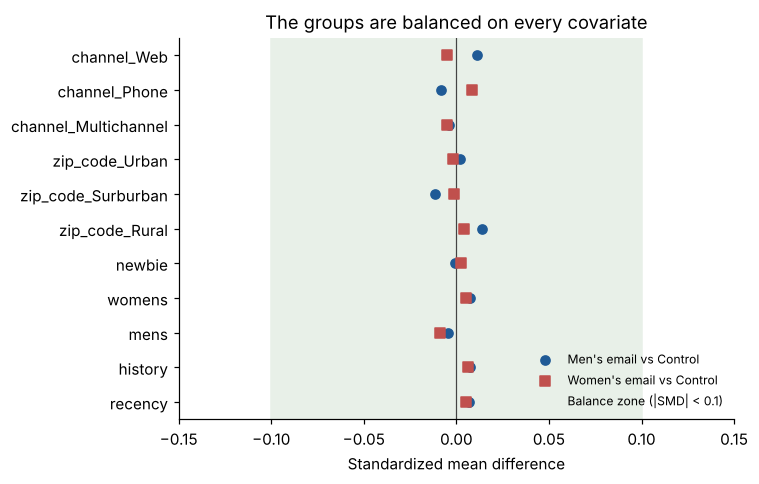

In [8]:
fig, ax = plt.subplots(figsize=(7, 4.5))
y = np.arange(len(balance))
ax.scatter(balance.iloc[:, 0], y, color=COLORS["Mens"], label="Men's email vs Control", zorder=3)
ax.scatter(balance.iloc[:, 1], y, color=COLORS["Womens"], label="Women's email vs Control", marker="s", zorder=3)
ax.axvspan(-0.1, 0.1, color="#E8F0E8", zorder=0, label="Balance zone (|SMD| < 0.1)")
ax.axvline(0, color="#444", lw=0.8)
ax.set_yticks(y, balance.index)
ax.set_xlim(-0.15, 0.15)
ax.set_xlabel("Standardized mean difference")
ax.set_title("The groups are balanced on every covariate")
ax.legend(loc="lower right", fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / "01_covariate_balance.png", dpi=150, bbox_inches="tight")

In [9]:
print(f"Max |SMD|: {balance.abs().to_numpy().max():.4f}")

Max |SMD|: 0.0137


Every difference is well below 0.1. Randomization produced comparable groups, so a difference in outcomes can be attributed either to the email or to chance, and telling those two apart is exactly what the tests in notebook 02 do.

## 5. Spend distribution

Spend is the primary metric, and its shape determines which tests are appropriate.

In [10]:
spend_summary = df.groupby("group", observed=True).agg(
    customers=("spend", "size"),
    pct_zero_spend=("spend", lambda s: (s == 0).mean()),
    mean=("spend", "mean"),
    std_dev=("spend", "std"),
)
spend_summary

,customers,pct_zero_spend,mean,std_dev
group,,,,
Control,21306,0.9943,0.6528,11.5882
Mens,21307,0.9875,1.4226,17.7542
Womens,21387,0.9912,1.0772,15.1161


In [11]:
percentiles = buyers.groupby("group", observed=True)["spend"].describe(percentiles=[0.25, 0.5, 0.75, 0.9])
percentiles

,count,mean,std,min,25%,50%,75%,90%,max
group,,,,,,,,,
Control,122.0000,114.0027,103.0311,29.9900,35.0400,88.3650,146.1700,226.8820,499.0000
Mens,267.0000,113.5269,111.6828,29.9900,29.9900,66.9800,152.7200,262.7900,499.0000
Womens,189.0000,121.8948,105.7703,29.9900,35.2000,94.7100,163.7900,268.0380,499.0000


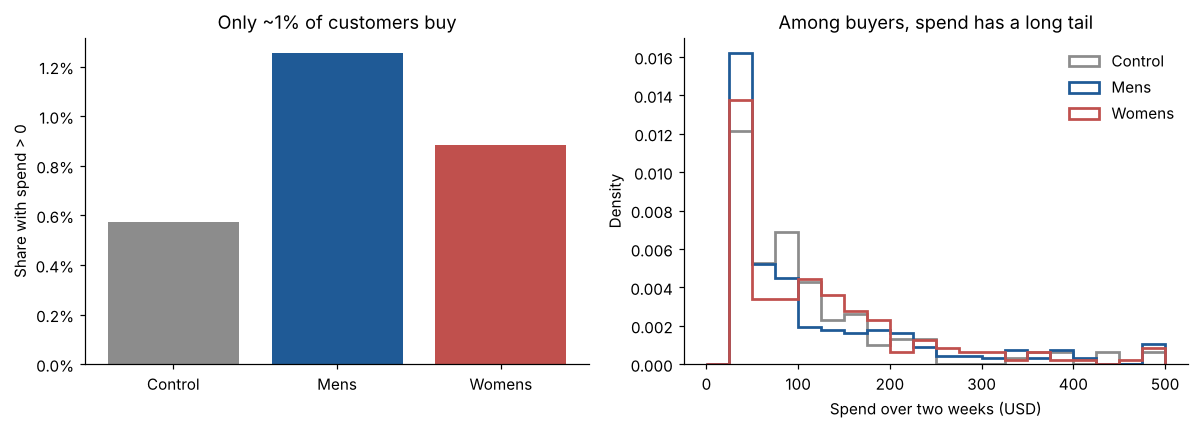

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

share = df.groupby("group", observed=True)["conversion"].mean()
axes[0].bar(share.index, share.values, color=[COLORS[g] for g in share.index])
axes[0].set_title("Only ~1% of customers buy")
axes[0].set_ylabel("Share with spend > 0")
axes[0].yaxis.set_major_formatter(lambda v, _: f"{v:.1%}")

bins = np.arange(0, 525, 25)
for g in GROUP_ORDER:
    axes[1].hist(buyers.loc[buyers.group == g, "spend"], bins=bins, histtype="step",
                 lw=1.8, color=COLORS[g], label=g, density=True)
axes[1].set_title("Among buyers, spend has a long tail")
axes[1].set_xlabel("Spend over two weeks (USD)")
axes[1].set_ylabel("Density")
axes[1].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / "01_spend_distribution.png", dpi=150, bbox_inches="tight")

More than 99% of customers do not buy, and among those who do, spend ranges from a few dollars up to 499. Therefore:

- In the control group, revenue per customer has a standard deviation about 18 times its mean: it is a very noisy metric.
- With ~21k customers per group, the central limit theorem should make the difference in means approximately normal, but I confirm it with a bootstrap in notebook 02.
- I do not trim extreme values in the main analysis: they are real purchases and total revenue depends on them.

## 6. Statistical power: minimum detectable effect

How large did the effect need to be for the experiment to detect it with 80% probability (α = 0.05, two-sided)? I compute it with the variability of the control group, which is what would be known before launching the test.

In [13]:
n_t = int(counts["Mens"])
n_c = int(counts["Control"])
base = df[df.group == "Control"]

rows = []
for metric, label in [("visit", "Visit rate"), ("conversion", "Conversion rate"), ("spend", "Revenue per customer (USD)")]:
    mean = base[metric].mean()
    sd = base[metric].std()
    mde = minimum_detectable_effect(sd, n_t, n_c)
    rows.append({"metric": label, "control": mean, "mde_absolute": mde, "mde_relative": mde / mean})

mde = pd.DataFrame(rows).set_index("metric")
mde

,control,mde_absolute,mde_relative
metric,,,
Visit rate,0.1062,0.0084,0.0788
Conversion rate,0.0057,0.0020,0.3577
Revenue per customer (USD),0.6528,0.3145,0.4818


How to read the table:

- Visits: the experiment detects changes of less than 1 percentage point (~8% relative). It has plenty of power.
- Conversion: it detects changes of ~0.2 points, which is ~36% relative, because the base rate is very low.
- Revenue per customer: it only detects effects of ~0.31 USD per customer, almost half of control revenue (~48% relative).

This shapes the interpretation: if a campaign does not show a significant revenue effect, that does not mean it doesn't work. It may be a real effect smaller than what can be detected. For segments, which have fewer customers, power is even lower.

## Conclusion

| Check | Result |
|---|---|
| Data quality | No nulls or inconsistencies; spend capped at 499 USD (12 cases) |
| Sample ratio mismatch | No imbalance (p = 0.90) |
| Covariate balance | All \|SMD\| < 0.02 |
| Spend distribution | >99% zeros and a long tail; Welch + bootstrap will be used |
| Power | High for visits, low for revenue (MDE ≈ 48% of control) |

The experiment is valid to analyze as randomized. Next step: [`02_analysis.ipynb`](02_analysis.ipynb).